In [38]:
from pathlib import Path
from PIL import Image
import torch
# from transformers import pipeline
from transformers import AutoProcessor, AutoModelForMultimodalLM
# from datasets import load_dataset
import matplotlib.pyplot as plt

import time
from threading import Thread
from transformers import TextIteratorStreamer

from dotenv import load_dotenv
load_dotenv() 

True

In [39]:
img_path = Path("../data/test-penguin.jpeg")
img = Image.open(img_path)

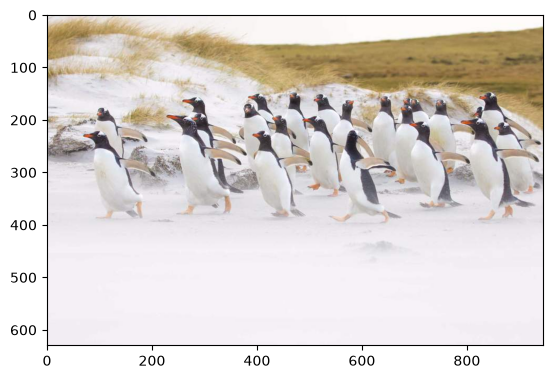

In [40]:
plt.imshow(img)
plt.show()


In [41]:
processor = AutoProcessor.from_pretrained("Qwen/Qwen3.5-2B")
model = AutoModelForMultimodalLM.from_pretrained("Qwen/Qwen3.5-2B", device_map="auto")

Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

Some parameters are on the meta device because they were offloaded to the disk.


In [42]:
print(model.device)
#If the return is `mps`, it confirms it is running on Apple Silicon.

mps:0


In [43]:
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": img},
            {"type": "text", "text": "What animal is in the image?"}
        ]
    },
] 

inputs = processor.apply_chat_template(
	messages,
	add_generation_prompt=True,
	tokenize=True,
	return_dict=True,
	return_tensors="pt",
).to(model.device)

In [ ]:
def generate_with_throughput(model, processor, inputs, **generate_kwargs):
    prompt_len = inputs["input_ids"].shape[-1]
    streamer = TextIteratorStreamer(
        processor.tokenizer,
        skip_prompt=True,
        skip_special_tokens=True,
    )
    kwargs = dict(**inputs, streamer=streamer, **generate_kwargs)

    t0 = time.perf_counter()
    thread = Thread(target=model.generate, kwargs=kwargs)
    thread.start()

    chunks = []
    for text in streamer:          # tokens appear here as they're generated
        print(text, end="", flush=True)
        chunks.append(text)

    thread.join()
    elapsed = time.perf_counter() - t0
    print()  # newline after stream

    # rough token count from output ids if you also want exact counts:
    # re-run without streamer, or encode the joined text:
    new_tokens = len(processor.tokenizer.encode("".join(chunks), add_special_tokens=False))
    tok_per_sec = new_tokens / elapsed if elapsed > 0 else float("nan")

    return "".join(chunks), {
        "generated_tokens": new_tokens,
        "wall_time_s": elapsed,
        "tokens_per_s": tok_per_sec,
    }

In [45]:
text, stats = generate_with_throughput(
    model, processor, inputs, max_new_tokens=128
)
print(stats)

The animals in the image are **penguins**, specifically **gentoo penguins** (*Pygoscelis adeliae*).

Here’s how you can tell:

- **Appearance**: They have black-and-white plumage, a distinctive orange beak, and white patches around their eyes (often called “eye rings”).
- **Behavior**: The group is walking together across a snowy or sandy beach — typical behavior for penguin colonies, especially during migration or breeding season.
- **Location context**: Gentoo penguins are native to the southern tip of South America (Chile and Argentina), but they are also found in
{'generated_tokens': 128, 'wall_time_s': 64.75320479199945, 'tokens_per_s': 1.9767361385612063}
